<a href="https://colab.research.google.com/github/EhsanGhasemi423/INFS-8368/blob/main/RNN_P4_RNN_model.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

## Recurrent Neural Networks (RNNs)

Earlier, we saw that an **n-gram language model** predicts the next token using only a fixed number of previous tokens.

For example:

- Bigram → uses the previous 1 token
- Trigram → uses the previous 2 tokens
- Larger n-gram → uses more previous tokens

We could try to capture longer dependencies by increasing $n$.

However, this creates a problem: **the number of possible token combinations grows extremely quickly.**

If the vocabulary contains $|V|$ possible tokens, an n-gram model may need to deal with approximately

$$
|V|^n
$$

possible combinations.

For example, suppose our vocabulary contains 10,000 words.

For a bigram:

$$
10{,}000^2 = 100{,}000{,}000
$$

possible word combinations.

For a trigram:

$$
10{,}000^3 = 1{,}000{,}000{,}000{,}000
$$

possible combinations.

So simply increasing $n$ becomes impractical.

### The RNN Approach

Instead of explicitly storing probabilities for huge numbers of previous-token combinations, an RNN maintains a **hidden state**.

The hidden state carries information about what the RNN has seen previously.

At time step $t$, the RNN uses:

- $x_t$ = current input
- $h_{t-1}$ = previous hidden state

to calculate:

$$
h_t = f(x_t, h_{t-1})
$$

So conceptually:

**current input + previous memory → new memory**

$$
x_t + h_{t-1} \rightarrow h_t
$$

The new hidden state is then passed to the next time step.

> **Key idea:** Instead of increasing the n-gram size and storing an enormous number of token combinations, an RNN uses a hidden state to carry information from previous time steps.

In [ ]:
!pip install --q D2l --no-deps

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 111.7/111.7 kB 4.4 MB/s eta 0:00:00


In [ ]:
import tensorflow as tf
from d2l import tensorflow as d2l


## Neural Networks Without Hidden States

Before introducing RNNs, consider a standard feedforward neural network.

For an input $X$, a hidden layer computes:

$$
H = \phi(XW_{xh} + b_h)
$$

and the output is:

$$
O = HW_{hq} + b_q
$$

The important point is that the output depends only on the **current input**.

There is no information carried from one time step to the next.

For example, if we process a sequence:

`the → time → machine`

a standard feedforward network processes each input independently. It does not automatically remember that it previously saw `the` and `time`.

> **Limitation:** A standard feedforward neural network has no memory of previous time steps.

This is a problem for sequence data, where the meaning or prediction at the current time step often depends on what happened earlier.



### This motivates the RNN

An RNN introduces a **hidden state** that is passed from one time step to the next:

$$
h_t = f(x_t, h_{t-1})
$$

So the RNN uses both:

- the current input $x_t$
- information from previous time steps $h_{t-1}$

> **Key idea:** The major difference is not simply having a hidden layer.  
> An RNN has a **hidden state that is recurrently carried through time**.

## Recurrent Neural Networks with Hidden States

The key difference between a standard neural network and an RNN is that an RNN carries information from the **previous time step** through a hidden state.

At time step $t$, the hidden state is calculated as:

$$
H_t =
\phi(
X_tW_{xh}
+
H_{t-1}W_{hh}
+
b_h
)
$$

where:

- $X_t$ = input at the current time step
- $H_{t-1}$ = hidden state from the previous time step
- $W_{xh}$ = weights from the input to the hidden state
- $W_{hh}$ = recurrent weights from the previous hidden state to the current hidden state
- $b_h$ = bias
- $\phi$ = activation function
- $H_t$ = new hidden state

The important new term is:

$$
H_{t-1}W_{hh}
$$

This term allows information from the **previous time step** to influence the current hidden state.



### How Information Moves Through the RNN

Conceptually:

$$
(X_t,\;H_{t-1})
\longrightarrow
H_t
\longrightarrow
O_t
$$

The current hidden state $H_t$ has two roles:

1. It is used to calculate the output at the current time step.
2. It is passed forward to help calculate $H_{t+1}$.

The output is calculated as:

$$
O_t = H_tW_{hq}+b_q
$$

So information flows through time as:

$$
H_{t-1}
\rightarrow
H_t
\rightarrow
H_{t+1}
\rightarrow \cdots
$$

This recurrent connection gives the RNN its **memory**.



### Example

Suppose the RNN reads:

`the → time → machine`

When it reads `the`, it creates a hidden state containing information about `the`.

When it then reads `time`, the new hidden state depends on both:

- the current token `time`
- the previous hidden state containing information about `the`

Therefore, when predicting the next token, the model can use information from the sequence it has already processed.

> **Key idea:** An RNN does not process each input independently.  
> Its hidden state carries information from previous time steps forward through the sequence.



### Shared Parameters

The same weight matrices

$$
W_{xh},\quad W_{hh},\quad W_{hq}
$$

are reused at every time step.

The RNN therefore does **not** create a new set of parameters for every position in the sequence.

> This parameter sharing allows the same RNN to process sequences of different lengths without the number of model parameters growing with the number of time steps.

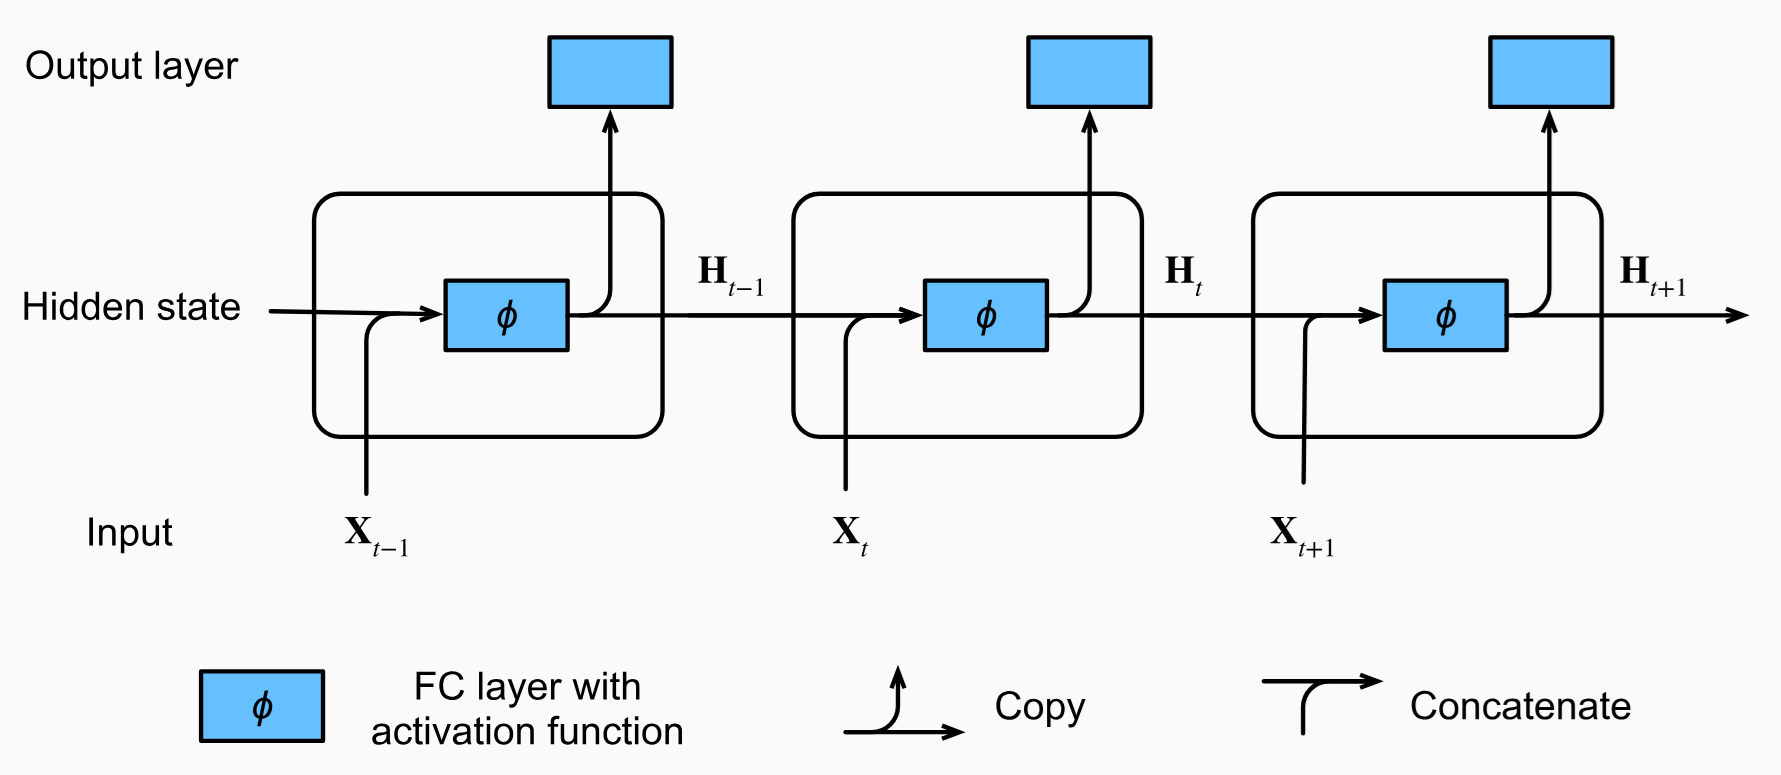

## RNN-Based Character-Level Language Model

Now we can use the RNN to perform **next-token prediction**.

In this example, each token is a **character**.

For the word:

`machine`

we create:

Input:  `m a c h i n`  
Target: `a c h i n e`

The target sequence is the original sequence shifted forward by one character.

Therefore, at each time step the RNN learns to predict the **next character**:

- `m` → predict `a`
- `ma` → predict `c`
- `mac` → predict `h`
- `mach` → predict `i`
- `machi` → predict `n`
- `machin` → predict `e`



The RNN does not simply look at the current character. Its **hidden state carries information from previous characters**.

For example, at time step 3:

`m → a → c`

the hidden state contains information from the sequence seen so far, and the model tries to predict:

`h`



### From Hidden State to Prediction

At each time step:

**current character + previous hidden state → new hidden state → output**

The output layer produces scores for all possible characters.  
**Softmax** converts these scores into probabilities.

For example:

`P(h) = 0.80`  
`P(a) = 0.05`  
`P(e) = 0.03`  
`...`

Since the correct target is `h`, **cross-entropy loss** measures how far the model's prediction is from that correct target.

During training, the RNN learns its weights so that the probability assigned to the correct next character becomes higher.

> **Key idea:** The RNN uses its hidden state as memory of the sequence seen so far and uses that memory to predict the next token.

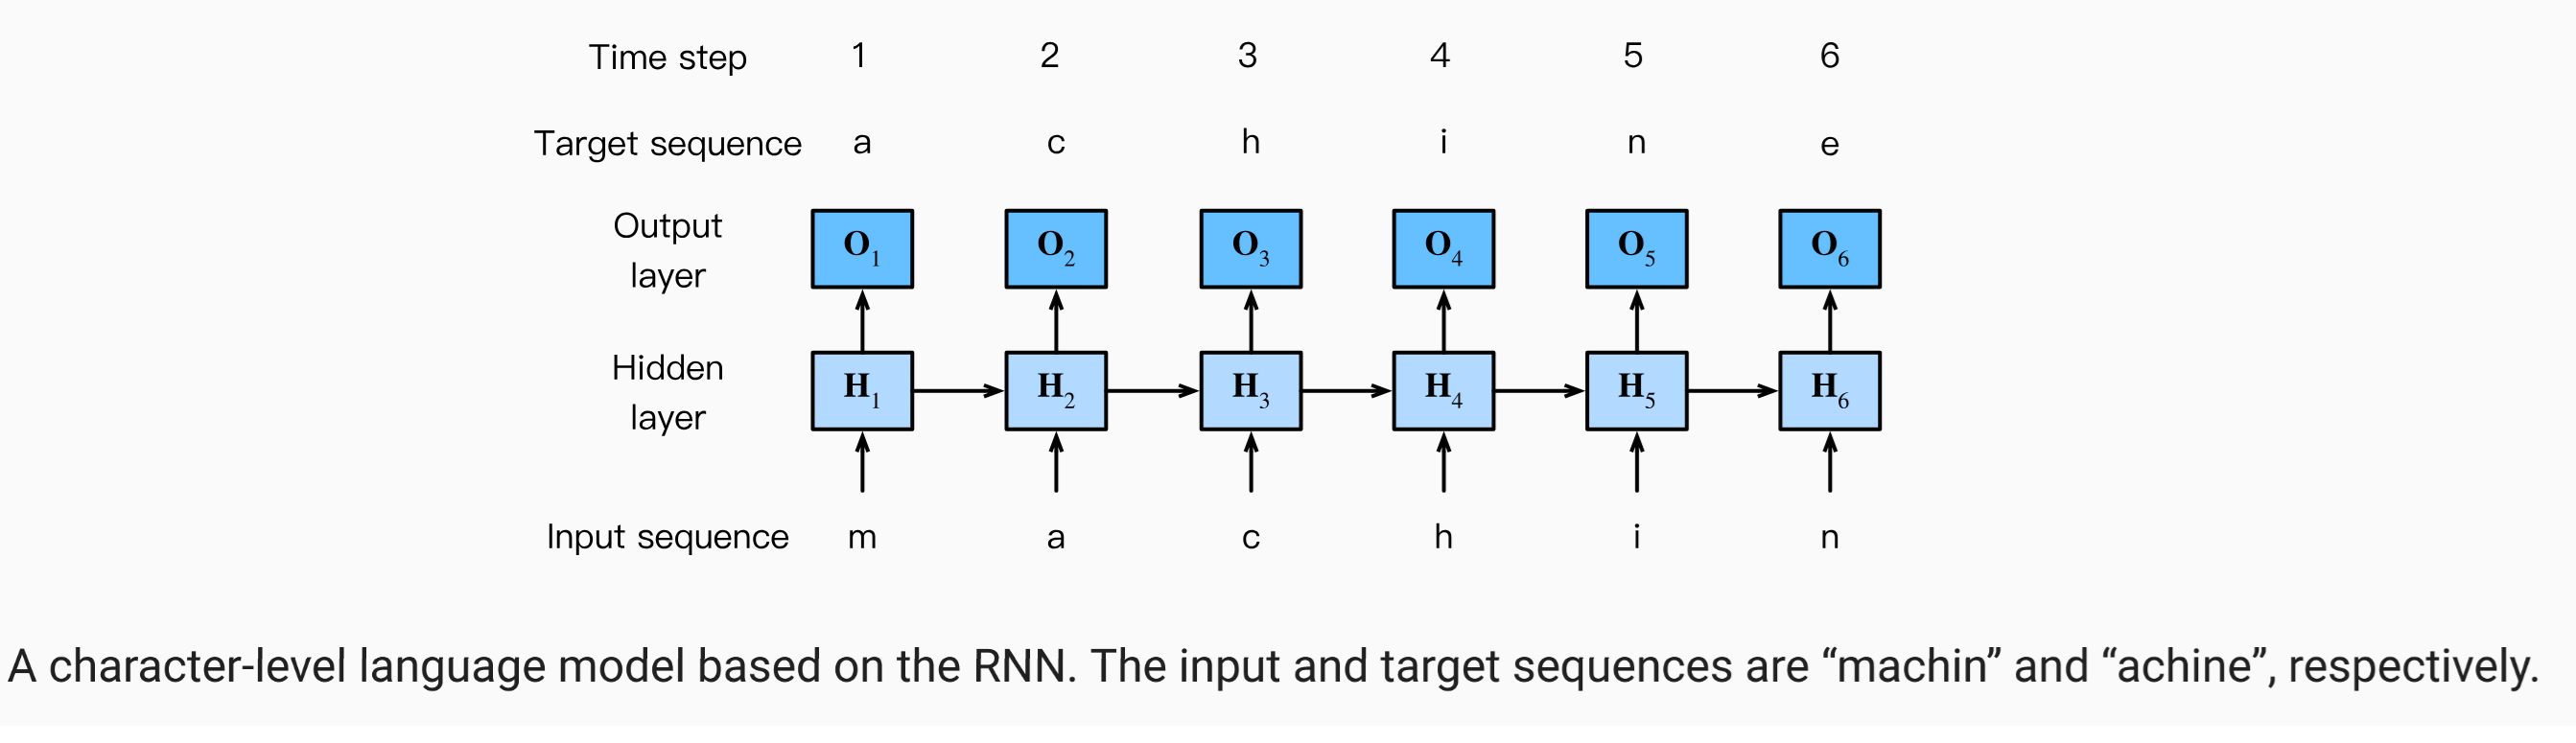

L=−logP(correct character)

## Summary

A **Recurrent Neural Network (RNN)** is designed to process sequential data.

At each time step, the RNN combines:

- the **current input** $X_t$
- the **previous hidden state** $H_{t-1}$

to calculate a new hidden state:

$$
H_t = \phi(X_tW_{xh} + H_{t-1}W_{hh} + b_h)
$$

The hidden state acts as the RNN's **memory**, carrying information from earlier time steps forward through the sequence.

The output is then calculated from the current hidden state:

$$
O_t = H_tW_{hq} + b_q
$$

An important feature of RNNs is **parameter sharing**: the same weight matrices are reused at every time step. Therefore, the number of model parameters does not increase simply because the sequence becomes longer.

For language modeling, this allows the RNN to use previous characters or words to predict the **next token**.